# Phase 5 — Controlled URL-only ML Experiments

## Objective

Compare three baseline classifiers using only numerical features recalculated from each raw URL by the Phase 4 canonical extractor. The positive class is **phishing** (`y=1`); legitimate is `y=0`. Source labels remain unchanged in the CSV. No webpage requests, DNS, Threat Intelligence, SHAP, model tuning, or application code are used.

The test partition is reserved until the baseline configurations, validation analysis, threshold review, and training-only cross-validation are complete. Results apply to this dataset and feature distribution, not to all phishing websites.

## 1. Environment and experiment configuration

This notebook calls the reusable construction, split, metrics, and model utilities under `src/ml/experiments.py`. Feature names and order come from `src/features/schema.py`. Random operations use seed 2026.

In [1]:
from pathlib import Path
import os, tempfile, sys, json, hashlib
ROOT=next((p for p in [Path.cwd(),*Path.cwd().parents] if (p/'data/raw/PhiUSIIL_Phishing_URL_Dataset.csv').exists()),None)
assert ROOT is not None, 'Could not locate project root containing the raw dataset'
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
os.environ.setdefault('MPLCONFIGDIR',str(Path(tempfile.gettempdir())/'phiusiil-ml-matplotlib'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import roc_curve, precision_recall_curve
from src.features import FEATURE_SCHEMA, FEATURE_SCHEMA_VERSION
from src.ml.experiments import (MODEL_FEATURE_NAMES,RANDOM_STATE,build_dataset,group_aware_three_way_split,
 make_baseline_models,validation_results,threshold_results,group_cross_validation,feature_importance_tables,
 calculate_metrics,dataset_sha256,runtime_versions,save_model_artifact)
sns.set_theme(style='whitegrid',context='notebook')
DATA_PATH=ROOT/'data/raw/PhiUSIIL_Phishing_URL_Dataset.csv'
CONFIG_PATH=ROOT/'ml/experiment_config.json'
config=json.loads(CONFIG_PATH.read_text(encoding='utf-8'))
print('Python/runtime:',runtime_versions())
print('Dataset SHA-256:',dataset_sha256(DATA_PATH))
print('Schema version:',FEATURE_SCHEMA_VERSION,'| seed:',RANDOM_STATE)

Python/runtime: {'python': '3.12.10', 'pandas': '3.1.0', 'numpy': '2.5.4', 'scikit_learn': '1.9.1', 'xgboost': '3.4.1', 'joblib': '1.6.0'}
Dataset SHA-256: a236549cd369cd80bd478ff8e1779cbf44c58d5c3f79f7a51a1adbed7d06d1c6
Schema version: 1.0.0 | seed: 2026


## 2. Dataset construction through the canonical extractor

For every row, the pipeline calls `extract_url_features(URL)`. The model matrix is then selected by type and canonical schema order. `Domain` is excluded from predictors because it is a high-cardinality site identifier; `FILENAME`, raw `URL`, `Title`, and all precomputed UCI features are not model inputs. Labels are mapped only in memory: source `0` → phishing-positive `1`; source `1` → legitimate `0`.

In [2]:
built=build_dataset(DATA_PATH)
X,y,urls=built.X,built.y,built.urls
quality=built.quality
print('Rows:',len(X),'| numerical features:',X.shape[1])
print('Canonical model feature order:',tuple(X.columns))
print('Extractor schema order:',tuple(FEATURE_SCHEMA[i].name for i in range(len(FEATURE_SCHEMA))))
print('Raw labels preserved in source file; transformed positive class is phishing (1).')
display(pd.DataFrame([{'feature':s.name,'type':s.python_type.__name__,'PhiUSIIL column':s.phiusiil_column,
                       'used as numeric model input':s.name in MODEL_FEATURE_NAMES,'caveat':s.caveat}
                      for s in FEATURE_SCHEMA]))

Rows: 235795 | numerical features: 8
Canonical model feature order: ('URLLength', 'DomainLength', 'IsDomainIP', 'NoOfDegitsInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'IsHTTPS')
Extractor schema order: ('URLLength', 'Domain', 'DomainLength', 'IsDomainIP', 'NoOfDegitsInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'IsHTTPS')
Raw labels preserved in source file; transformed positive class is phishing (1).


,feature,type,PhiUSIIL column,used as numeric model input,caveat
0,URLLength,int,URLLength,True,"Deterministic definition, but EDA validation f..."
1,Domain,str,Domain,False,High-cardinality identifier; may include useri...
2,DomainLength,int,DomainLength,True,"Counts userinfo and port when present, matchin..."
3,IsDomainIP,int,IsDomainIP,True,Does not resolve DNS. UCI appears to flag some...
4,NoOfDegitsInURL,int,NoOfDegitsInURL,True,The UCI values differ on a small subset; exact...
5,NoOfEqualsInURL,int,NoOfEqualsInURL,True,UCI mismatches observed mainly at trailing del...
6,NoOfQMarkInURL,int,NoOfQMarkInURL,True,A trailing standalone question mark is counted...
7,NoOfAmpersandInURL,int,NoOfAmpersandInURL,True,Substantial UCI mismatches suggest different a...
8,IsHTTPS,int,IsHTTPS,True,Scheme-only; does not test TLS. Some UCI posit...


## 3. Data quality checks before splitting

The audit reports duplicate URLs and duplicate feature vectors without removing them. Duplicate feature vectors can arise from distinct URLs mapping to the same eight numeric values; label conflicts are counted because such rows are inherently indistinguishable to these inputs. Any missing or non-finite model value causes the construction pipeline to stop rather than silently discard a row.

In [3]:
quality_table=pd.DataFrame([{'check':k,'result':v} for k,v in quality.items()])
display(quality_table)
source_class=pd.DataFrame({'source label':[0,1], 'meaning':['phishing','legitimate'],
                           'rows':[quality['source_label_counts'][0],quality['source_label_counts'][1]]})
display(source_class)
assert quality['rows_excluded']==0
assert quality['missing_feature_values']==0 and quality['infinite_feature_values']==0
assert quality['conflicting_duplicate_url_groups']==0

,check,result
0,row_count,235795
1,feature_count,8
2,missing_feature_values,0
3,infinite_feature_values,0
4,duplicate_url_occurrences,425
5,distinct_repeated_urls,425
6,conflicting_duplicate_url_groups,0
7,duplicate_feature_vector_occurrences,218054
8,conflicting_duplicate_feature_vector_groups,132
9,fully_duplicated_source_rows,0


,source label,meaning,rows
0,0,phishing,100945
1,1,legitimate,134850


## 4. URL-group-aware train/validation/test split

Unique exact URL strings are shuffled within each transformed class using a seeded NumPy generator. The shuffled groups are assigned to 20 approximately equal group folds; folds 0–13 are training, 14–16 validation, and 17–19 test. Every repeated URL stays in one partition. Since groups are assigned whole, row proportions may differ slightly from 70/15/15. The code verifies all pairwise URL intersections are empty.

In [4]:
partitions=group_aware_three_way_split(X,y,urls,random_state=RANDOM_STATE)
url_sets={name:set(urls.iloc[idx].astype(str)) for name,idx in partitions.items()}
for a,b in [('train','validation'),('train','test'),('validation','test')]:
    assert not (url_sets[a]&url_sets[b]),f'URL leakage: {a}/{b}'
split_summary=pd.DataFrame([{'partition':name,'rows':len(idx),'row_share_pct':100*len(idx)/len(X),
                             'distinct_URL_groups':len(url_sets[name])}
                            for name,idx in partitions.items()]).set_index('partition')
display(split_summary)
print('Pairwise URL intersections:',{f'{a}/{b}':len(url_sets[a]&url_sets[b]) for a,b in
      [('train','validation'),('train','test'),('validation','test')]})
X_train,y_train,urls_train=X.iloc[partitions['train']],y.iloc[partitions['train']],urls.iloc[partitions['train']]
X_validation,y_validation=X.iloc[partitions['validation']],y.iloc[partitions['validation']]
X_test,y_test=X.iloc[partitions['test']],y.iloc[partitions['test']]

,rows,row_share_pct,distinct_URL_groups
partition,,,
train,165062,70.002333,164762
validation,35365,14.998198,35304
test,35368,14.999470,35304


Pairwise URL intersections: {'train/validation': 0, 'train/test': 0, 'validation/test': 0}


## 5. Preprocessing and fixed baseline configurations

`StandardScaler` is inside the Logistic Regression pipeline, so it is fitted only when that pipeline is fitted on training data (and separately inside each CV fold). Random Forest and XGBoost use raw numeric values and need no scaling. No learned preprocessing is fit before splitting.

In [5]:
models=make_baseline_models(random_state=RANDOM_STATE)
for name,estimator in models.items(): print(name,estimator)

Logistic Regression Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(max_iter=2000, random_state=2026))])
Random Forest RandomForestClassifier(n_estimators=200, n_jobs=1, random_state=2026)
XGBoost XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.9, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=1,
          

## 6. Fit baselines on training only; compare on validation

At threshold 0.5, the helper reports phishing-positive precision, recall, F1, ROC-AUC, average precision (reported as PR-AUC), confusion counts, FPR, and FNR. Confusion definitions are: TP = phishing correctly flagged; FP = legitimate incorrectly flagged; TN = legitimate correctly cleared; FN = phishing missed. No test prediction is requested in this section.

In [6]:
fitted_models,validation_metrics=validation_results(models,X_train,y_train,X_validation,y_validation)
validation_metrics

,threshold,accuracy,precision_phishing,recall_phishing,f1_phishing,roc_auc,pr_auc,tn_legitimate_correct,fp_legitimate_flagged_phishing,fn_phishing_missed,tp_phishing_correct,false_positive_rate,false_negative_rate
model,,,,,,,,,,,,,
Logistic Regression,0.5,0.972657,0.995317,0.940551,0.967159,0.995074,0.995818,20159,67,900,14239,0.003313,0.059449
Random Forest,0.5,0.994175,0.999599,0.986789,0.993153,0.996077,0.996946,20220,6,200,14939,0.000297,0.013211
XGBoost,0.5,0.967143,0.988126,0.934474,0.960551,0.994566,0.995065,20056,170,992,14147,0.008405,0.065526


## 7. Validation threshold analysis

Thresholds below are evaluated on the validation set only. Lowering the threshold may increase phishing recall and false positives; raising it may lower false positives while missing more phishing. These operating points do not finalize a production threshold.

,model,threshold,precision_phishing,recall_phishing,f1_phishing,fp_legitimate_flagged_phishing,fn_phishing_missed,false_positive_rate,false_negative_rate
0,Random Forest,0.1,0.990597,0.988176,0.989385,142,179,0.007021,0.011824
1,Random Forest,0.2,0.996002,0.987318,0.991641,60,192,0.002966,0.012682
2,Random Forest,0.3,0.997996,0.987053,0.992495,30,196,0.001483,0.012947
3,Random Forest,0.4,0.999398,0.986855,0.993087,9,199,0.000445,0.013145
4,Random Forest,0.5,0.999599,0.986789,0.993153,6,200,0.000297,0.013211
5,Random Forest,0.6,0.999732,0.986723,0.993185,4,201,0.000198,0.013277
6,Random Forest,0.7,0.999799,0.986459,0.993084,3,205,0.000148,0.013541
7,Random Forest,0.8,0.999933,0.985468,0.992648,1,220,0.000049,0.014532
8,Random Forest,0.9,1.000000,0.985402,0.992647,0,221,0.000000,0.014598
9,Logistic Regression,0.1,0.888087,0.992272,0.937293,1893,117,0.093592,0.007728


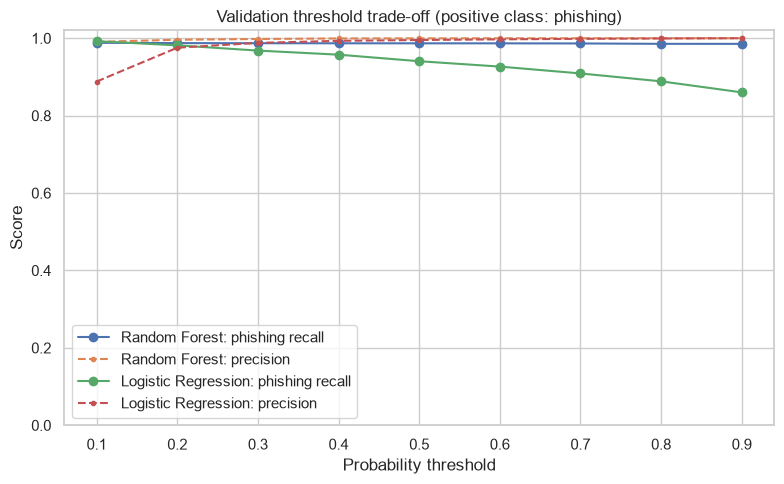

In [7]:
threshold_grid=tuple(config['thresholds_for_validation_analysis'])
top_two=validation_metrics.sort_values(['pr_auc','recall_phishing'],ascending=False).head(2).index.tolist()
threshold_tables={}
for name in top_two:
    probs=fitted_models[name].predict_proba(X_validation)[:,1]
    table=threshold_results(y_validation,probs,thresholds=threshold_grid)
    table.insert(0,'model',name)
    threshold_tables[name]=table
display(pd.concat(threshold_tables.values(),ignore_index=True)[['model','threshold','precision_phishing','recall_phishing',
 'f1_phishing','fp_legitimate_flagged_phishing','fn_phishing_missed','false_positive_rate','false_negative_rate']])
fig,ax=plt.subplots(figsize=(8,5))
for name,table in threshold_tables.items():
    ax.plot(table.threshold,table.recall_phishing,marker='o',label=f'{name}: phishing recall')
    ax.plot(table.threshold,table.precision_phishing,marker='.',linestyle='--',label=f'{name}: precision')
ax.set(title='Validation threshold trade-off (positive class: phishing)',xlabel='Probability threshold',ylabel='Score')
ax.set_ylim(0,1.02); ax.legend(); plt.tight_layout(); plt.show()

## 8. Group-aware cross-validation on training only

Five-fold CV is limited to the training partition. Exact URL groups are shuffled within each class into folds; the helper checks that no URL appears on both sides of any fold. The Logistic Regression scaler is refit inside each CV training fold. The validation and test partitions are not passed into cross-validation.

In [8]:
cv_metrics=group_cross_validation(models,X_train,y_train,urls_train,random_state=RANDOM_STATE,n_splits=5)
display(cv_metrics)

,accuracy_mean,accuracy_std,precision_phishing_mean,precision_phishing_std,recall_phishing_mean,recall_phishing_std,f1_phishing_mean,f1_phishing_std,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,false_negative_rate_mean,false_negative_rate_std
model,,,,,,,,,,,,,,
Logistic Regression,0.968103,0.001248,0.994376,0.000561,0.930758,0.002718,0.961514,0.001543,0.994167,0.000528,0.994936,0.000421,0.069242,0.002718
Random Forest,0.993439,0.000512,0.999154,0.000234,0.985509,0.001100,0.992284,0.000606,0.995563,0.000373,0.996509,0.000255,0.014491,0.001100
XGBoost,0.969236,0.002338,0.990209,0.000888,0.937409,0.005233,0.963080,0.002898,0.994638,0.000345,0.995035,0.000201,0.062591,0.005233


## 9. Candidate selection before opening the test set

Selection uses validation PR-AUC first. Candidates within 0.01 PR-AUC of the best are treated as close; among them prefer higher training-only CV PR-AUC, then validation phishing recall, then the simpler model (Logistic Regression, Random Forest, XGBoost). Accuracy is not the selection criterion. The locked candidate and this rationale are recorded before final test metrics are calculated. The threshold remains an analysis topic, not a finalized operating point.

In [9]:
best_val_ap=float(validation_metrics.pr_auc.max())
near_candidates=[name for name in validation_metrics.index if validation_metrics.loc[name,'pr_auc']>=best_val_ap-0.01]
simplicity={'Logistic Regression':3,'Random Forest':2,'XGBoost':1}
candidate_name=sorted(near_candidates,key=lambda name:(cv_metrics.loc[name,'pr_auc_mean'],
 validation_metrics.loc[name,'recall_phishing'],simplicity[name]),reverse=True)[0]
candidate_threshold=0.5
print('Locked candidate before test evaluation:',candidate_name)
print('Validation PR-AUC best:',best_val_ap,'| near-tie set:',near_candidates)
print('Baseline reporting threshold:',candidate_threshold,'(not a finalized deployment threshold)')

Locked candidate before test evaluation: Random Forest
Validation PR-AUC best: 0.9969456215184292 | near-tie set: ['Logistic Regression', 'Random Forest', 'XGBoost']
Baseline reporting threshold: 0.5 (not a finalized deployment threshold)


## 10. Final held-out test evaluation

Only after candidate selection and CV, calculate the fixed-threshold test metrics for all three frozen baseline fits. These scores are for comparison/reporting; they are not fed back into model or threshold selection.

In [10]:
test_rows=[]
test_probabilities={}
for name,estimator in fitted_models.items():
    probabilities=estimator.predict_proba(X_test)[:,1]
    test_probabilities[name]=probabilities
    test_rows.append({'model':name,**calculate_metrics(y_test,probabilities,threshold=0.5)})
test_metrics=pd.DataFrame(test_rows).set_index('model')
display(test_metrics[['accuracy','precision_phishing','recall_phishing','f1_phishing','roc_auc','pr_auc',
 'false_positive_rate','false_negative_rate','tn_legitimate_correct','fp_legitimate_flagged_phishing',
 'fn_phishing_missed','tp_phishing_correct']])
print('Final test set was not used for fit, preprocessing, threshold choice, or candidate selection.')

,accuracy,precision_phishing,recall_phishing,f1_phishing,roc_auc,pr_auc,false_positive_rate,false_negative_rate,tn_legitimate_correct,fp_legitimate_flagged_phishing,fn_phishing_missed,tp_phishing_correct
model,,,,,,,,,,,,
Logistic Regression,0.970397,0.995640,0.934949,0.964340,0.994704,0.995400,0.003065,0.065051,20164,62,985,14157
Random Forest,0.993299,0.998862,0.985471,0.992121,0.995588,0.996414,0.000841,0.014529,20209,17,220,14922
XGBoost,0.965081,0.987931,0.929798,0.957983,0.994638,0.994872,0.008504,0.070202,20054,172,1063,14079


Final test set was not used for fit, preprocessing, threshold choice, or candidate selection.


## 11. ROC and precision-recall curves

Curves use the held-out test probabilities after the candidate has been locked. The PR plot identifies phishing as the positive class; its baseline is the phishing prevalence in the test partition.

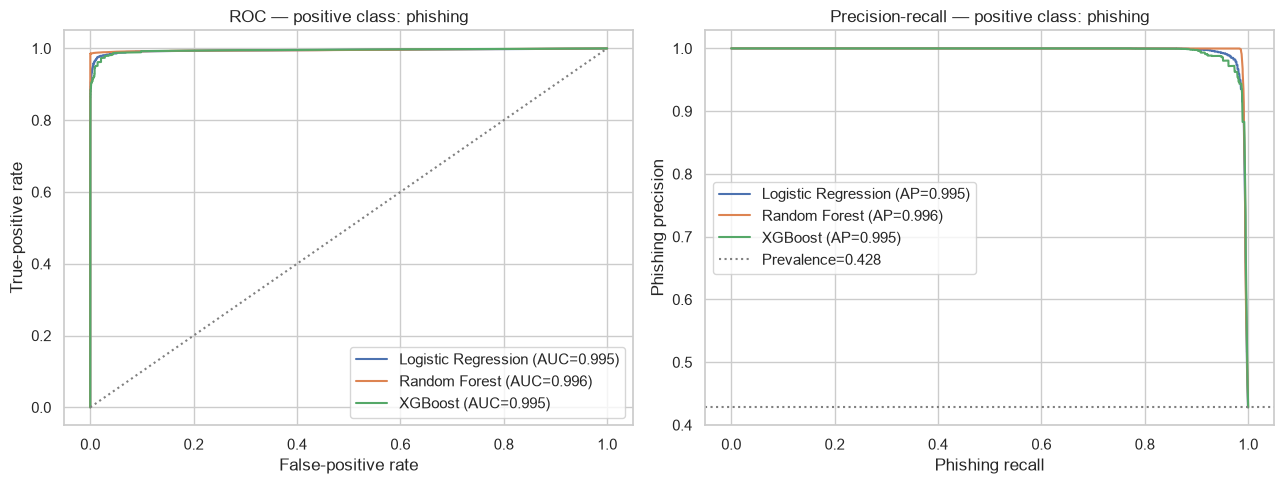

In [11]:
fig,axes=plt.subplots(1,2,figsize=(13,5))
for name,prob in test_probabilities.items():
    fpr,tpr,_=roc_curve(y_test,prob,pos_label=1)
    axes[0].plot(fpr,tpr,label=f'{name} (AUC={test_metrics.loc[name,"roc_auc"]:.3f})')
    precision,recall,_=precision_recall_curve(y_test,prob,pos_label=1)
    axes[1].plot(recall,precision,label=f'{name} (AP={test_metrics.loc[name,"pr_auc"]:.3f})')
axes[0].plot([0,1],[0,1],color='grey',linestyle=':'); axes[0].set(title='ROC — positive class: phishing',xlabel='False-positive rate',ylabel='True-positive rate')
axes[1].axhline(float(y_test.mean()),color='grey',linestyle=':',label=f'Prevalence={y_test.mean():.3f}')
axes[1].set(title='Precision-recall — positive class: phishing',xlabel='Phishing recall',ylabel='Phishing precision')
for ax in axes: ax.legend(loc='best')
plt.tight_layout(); plt.show()

## 12. Model feature importance (not SHAP)

Random Forest and XGBoost built-in importances and standardized Logistic Regression coefficients are model-specific summaries. They are not SHAP explanations and do not establish causal relevance. The Logistic Regression coefficients apply to standardized features.

Logistic Regression


,feature,coefficient_standardized,abs_value
0,URLLength,93.120611,93.120611
1,DomainLength,-20.334986,20.334986
3,NoOfDegitsInURL,11.327541,11.327541
2,IsDomainIP,10.670230,10.670230
7,IsHTTPS,-7.573709,7.573709
5,NoOfQMarkInURL,1.615328,1.615328
6,NoOfAmpersandInURL,0.355955,0.355955
4,NoOfEqualsInURL,0.345226,0.345226


Random Forest


,feature,importance
7,IsHTTPS,0.411839
0,URLLength,0.230286
3,NoOfDegitsInURL,0.191917
1,DomainLength,0.151539
5,NoOfQMarkInURL,0.007715
4,NoOfEqualsInURL,0.005367
6,NoOfAmpersandInURL,0.001239
2,IsDomainIP,0.000097


XGBoost


,feature,importance
7,IsHTTPS,0.621566
3,NoOfDegitsInURL,0.244945
0,URLLength,0.083208
1,DomainLength,0.047574
5,NoOfQMarkInURL,0.002707
2,IsDomainIP,0.000000
4,NoOfEqualsInURL,0.000000
6,NoOfAmpersandInURL,0.000000


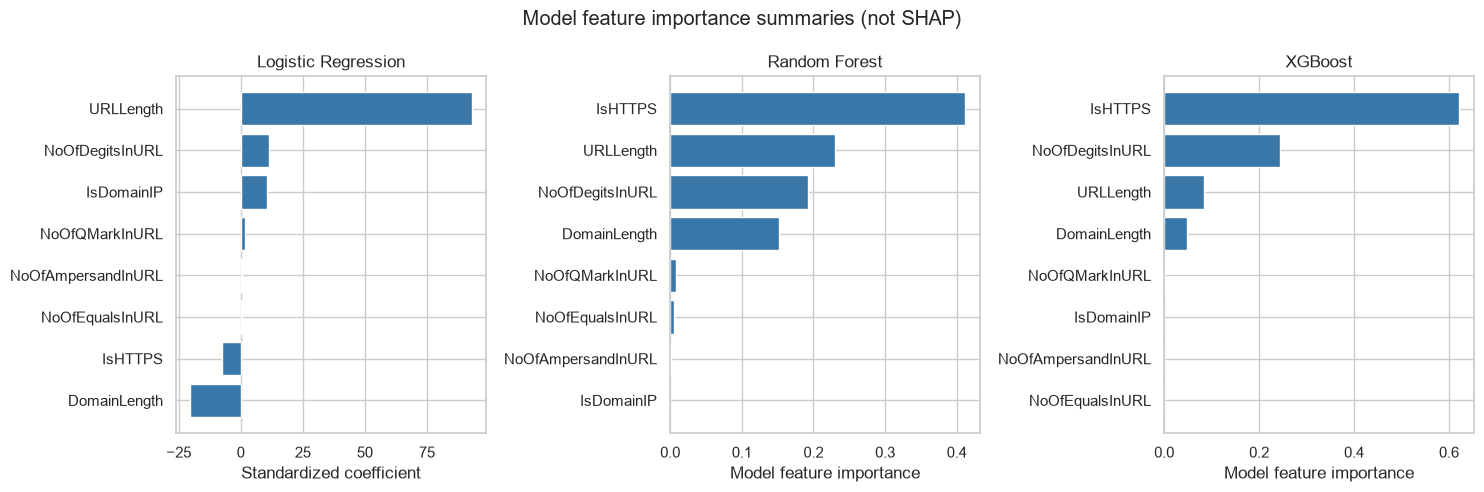

In [12]:
importance=feature_importance_tables(fitted_models,MODEL_FEATURE_NAMES)
for name,table in importance.items():
    print(name); display(table)
fig,axes=plt.subplots(1,3,figsize=(15,5))
for ax,(name,table) in zip(axes,importance.items()):
    value_col='coefficient_standardized' if name=='Logistic Regression' else 'importance'
    plot_table=table.sort_values(value_col)
    ax.barh(plot_table.feature,plot_table[value_col],color='#3977a8')
    ax.set(title=name,xlabel='Standardized coefficient' if name=='Logistic Regression' else 'Model feature importance')
fig.suptitle('Model feature importance summaries (not SHAP)'); plt.tight_layout(); plt.show()

## 13. Test comparison and conclusion

Interpret phishing recall/FNR alongside precision/FPR, PR-AUC, inference simplicity, interpretability, and later SHAP suitability. Results are dataset-specific and do not establish comprehensive or production-ready phishing protection.

In [13]:
comparison=test_metrics[['accuracy','precision_phishing','recall_phishing','f1_phishing','roc_auc','pr_auc',
 'false_positive_rate','false_negative_rate']].copy()
comparison['validation_pr_auc']=validation_metrics['pr_auc']
comparison['cv_pr_auc_mean']=cv_metrics['pr_auc_mean']
comparison['cv_pr_auc_std']=cv_metrics['pr_auc_std']
display(comparison.sort_values('pr_auc',ascending=False))
print('Selected candidate:',candidate_name)
print('Confusion-matrix positive class: phishing. Threshold 0.5 is retained as baseline only.')

,accuracy,precision_phishing,recall_phishing,f1_phishing,roc_auc,pr_auc,false_positive_rate,false_negative_rate,validation_pr_auc,cv_pr_auc_mean,cv_pr_auc_std
model,,,,,,,,,,,
Random Forest,0.993299,0.998862,0.985471,0.992121,0.995588,0.996414,0.000841,0.014529,0.996946,0.996509,0.000255
Logistic Regression,0.970397,0.995640,0.934949,0.964340,0.994704,0.995400,0.003065,0.065051,0.995818,0.994936,0.000421
XGBoost,0.965081,0.987931,0.929798,0.957983,0.994638,0.994872,0.008504,0.070202,0.995065,0.995035,0.000201


Selected candidate: Random Forest
Confusion-matrix positive class: phishing. Threshold 0.5 is retained as baseline only.


## 14. Save a versioned candidate artifact and provenance

The saved bundle is a research candidate, not a production model. It contains the fitted train-only estimator, numeric feature order, schema version, label mapping, and reproducibility metadata. A pre-existing artifact is never overwritten; a numbered run suffix is used when needed.

In [14]:
slug=candidate_name.lower().replace(' ','_')
artifact=ROOT/'models'/f'url_only_{slug}_seed{RANDOM_STATE}_candidate.joblib'
run=2
while artifact.exists():
    artifact=ROOT/'models'/f'url_only_{slug}_seed{RANDOM_STATE}_candidate_run{run:02d}.joblib'
    run+=1
metadata={
 'experiment_config':config,
 'dataset_sha256':dataset_sha256(DATA_PATH),
 'feature_schema_version':FEATURE_SCHEMA_VERSION,
 'feature_names':list(MODEL_FEATURE_NAMES),
 'positive_label':{'model_value':1,'meaning':'phishing','source_value':0},
 'split_rows':{name:int(len(idx)) for name,idx in partitions.items()},
 'candidate_selection':'validation PR-AUC within 0.01 of best; prefer training-only CV PR-AUC, phishing recall, then simplicity',
 'baseline_threshold':0.5,
 'threshold_finalized':False,
 'validation_metrics':validation_metrics.loc[candidate_name].to_dict(),
 'cross_validation_metrics':cv_metrics.loc[candidate_name].to_dict(),
 'test_metrics':test_metrics.loc[candidate_name].to_dict(),
 'runtime_versions':runtime_versions(),
}
saved_path=save_model_artifact(artifact,fitted_models[candidate_name],metadata)
print('Saved candidate artifact:',saved_path.relative_to(ROOT))
print('Artifact status: research candidate; fitted on training partition; no threshold finalized.')

Saved candidate artifact: models\url_only_random_forest_seed2026_candidate.joblib
Artifact status: research candidate; fitted on training partition; no threshold finalized.


## 15. Limitations and next phase boundary

Only eight numeric fields from the nine-field extractor output were modeled; raw `Domain` was excluded as a high-cardinality identifier. The source UCI values are not used as predictors. Several extractor-to-UCI calculations have unresolved source compatibility, so all training values were recomputed from the URL and must be recomputed the same way at inference. Feature-vector collisions (including mixed-label vectors) limit what these inputs can distinguish. Group-aware evaluation protects against exact URL overlap but not unseen-site, time, source, or distribution shifts. Threshold selection, SHAP, FastAPI, frontend, and Threat Intelligence remain out of scope.